## **Classwork: "What Did the Network See?" — Inside CNN Feature Maps**

**The Scenario**

Your CNN is training — but is it *actually* learning anything useful? This is the question every practitioner must answer before trusting a model. Today you will go inside the network: visualise what individual filters detect, understand how the *receptive field* grows layer by layer, and inspect how a bank of filters collectively describes an image. By the end, you will have the tools to diagnose a CNN the same way an engineer reads an X-ray.

## **Part 1: Conceptual Questions**

### **Question 1: What is a Feature Map?**

After a single convolutional layer with one 3×3 filter processes a grayscale image, you get a 2D output grid. What does each value in this output grid represent?

A) The original pixel brightness at that location, averaged over a 3×3 neighbourhood.

B) The degree to which the filter's pattern (e.g. a vertical edge, a diagonal) was present at that spatial location in the input.

C) The probability that a specific class (cat, dog, etc.) is present at that location.

D) The gradient of the loss with respect to the pixel at that location.

Please answer here

B) The degree to which the filter's pattern (e.g. a vertical edge, a diagonal) was present at that spatial location in the input.


### **Question 2: The Receptive Field**

Consider a CNN with **two successive** convolutional layers, each using a 3×3 kernel with stride 1 and no padding.

A single neuron in the *second* feature map (after the second convolution) corresponds to what region of the original input image?

A) A 3×3 region — the kernel is 3×3, so it always sees the same area.

B) A 5×5 region — stacking two 3×3 convolutions means each output neuron aggregates information from a 5×5 patch of the input.

C) A 9×9 region — the two kernels multiply (3×3 = 9).

D) The entire image — every convolution has a global receptive field.

Please answer here

B) A 5×5 region — stacking two 3×3 convolutions means each output neuron aggregates information from a 5×5 patch of the input.

### **Question 3: Many Filters, Many Feature Maps**

A convolutional layer has **32 filters**, each of size 3×3. It processes a **64×64 RGB image** (3 channels). What is the shape of the output volume (feature map stack), assuming stride 1 and no padding?

A) (64, 64, 3) — the input shape is preserved and the filters are not stacked.

B) (62, 62, 32) — each filter produces one 62×62 feature map, and 32 filters produce 32 feature maps.

C) (62, 62, 3) — the number of output channels equals the number of input channels.

D) (64, 64, 32) — convolution never changes spatial size.

Please answer here

B) A 5×5 region — stacking two 3×3 convolutions means each output neuron aggregates information from a 5×5 patch of the input.


## **Part 2: Numerical Reasoning**

### **Question 4: Receptive Field Calculation**

You are designing a CNN with the following architecture:

| Layer | Type | Kernel | Stride |
|---|---|---|---|
| 1 | Conv | 3×3 | 1 |
| 2 | MaxPool | 2×2 | 2 |
| 3 | Conv | 3×3 | 1 |

The receptive field of a neuron after layer $l$ can be computed iteratively:
$$RF_l = RF_{l-1} + (k_l - 1) \times \prod_{i=1}^{l-1} s_i$$
where $k_l$ is the kernel size and $s_i$ is the stride at layer $i$. Start with $RF_0 = 1$.

Calculate the receptive field of a neuron in the **output of Layer 3** with respect to the original input image. Show your working step by step.

Please show your working here

- After Layer 1: 
$$
  RF_{l-1} = 1 , k_{l} = 3 , s_{i} = 1   

  RF_{l} = 1 + (3-1)*1 

  RF_{1} = 3
$$

- After Layer 2 (MaxPool): 

$$
  RF_{l-1} = 3 , k_{l} = 2 , s_{i} = 2   

  RF_{l} = 3 + (2-1)*1

  RF_{2} = 4

$$
- After Layer 3: 

$$

  RF_{l-1} = 4 , k_{l} = 3 , s_{i} = 1   

  RF_{l} = 4 + (3-1)*1*2 

  RF_{3} = 8

$$


## **Part 3: Coding Challenge — Visualising What Filters Learn**

You will now build a multi-filter CNN layer from scratch and visualise *all* of its feature maps at once. This is exactly what researchers do to verify that a trained network is picking up meaningful patterns.

**Fill in the lines marked `## FILL IN`.**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# --- Synthetic test image: a cross on a noisy background ---
np.random.seed(0)
image = np.random.rand(32, 32) * 0.15  # low-level noise
image[14:18, 4:28] = 1.0   # horizontal bar
image[4:28, 14:18] = 1.0   # vertical bar

# --- A bank of 6 hand-crafted filters ---
filters = {
    "Vertical edge":    np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=float),
    "Horizontal edge":  np.array([[-1,-2,-1], [ 0, 0, 0], [ 1, 2, 1]], dtype=float),
    "Diagonal (\\)": np.array([[ 2, 1,-1], [ 1, 0,-1], [-1,-1,-2]], dtype=float),
    "Laplacian":        np.array([[ 0,-1, 0], [-1, 4,-1], [ 0,-1, 0]], dtype=float),
    "Blur":             np.ones((3, 3), dtype=float) / 9,
    "Emboss":           np.array([[-2,-1, 0], [-1, 1, 1], [ 0, 1, 2]], dtype=float),
}

print(f"Image shape: {image.shape}")
print(f"Number of filters: {len(filters)}")

Image shape: (32, 32)
Number of filters: 6


In [2]:
# --- Reuse your implementations from the previous notebook ---

def conv2d(image, kernel, stride=1, padding=0):
    H, W = image.shape
    K = kernel.shape[0]
    if padding > 0:
        image = np.pad(image, padding, mode='constant')
    out_H = (H - K + 2 * padding) // stride + 1
    out_W = (W - K + 2 * padding) // stride + 1
    feature_map = np.zeros((out_H, out_W))
    for i in range(out_H):
        for j in range(out_W):
            patch = image[i*stride : i*stride+K, j*stride : j*stride+K]
            feature_map[i, j] = np.sum(patch * kernel)
    return feature_map

def relu(x):
    return np.maximum(0, x)

def max_pool2d(feature_map, pool_size=2, stride=2):
    H, W = feature_map.shape
    out_H = (H - pool_size) // stride + 1
    out_W = (W - pool_size) // stride + 1
    pooled = np.zeros((out_H, out_W))
    for i in range(out_H):
        for j in range(out_W):
            patch = feature_map[i*stride : i*stride+pool_size, j*stride : j*stride+pool_size]
            pooled[i, j] = np.max(patch)
    return pooled

print("Helper functions loaded.")

Helper functions loaded.


In [3]:
# ---------------------------------------------------------------
# Task A: Apply every filter in the bank to the image
# and store the result (after ReLU) in a dictionary.
# ---------------------------------------------------------------

feature_maps = {}  # will store {filter_name: feature_map_after_relu}

for name, kernel in filters.items():
    ## FILL IN:
    ## 1. Apply conv2d to `image` with the current `kernel` (stride=1, padding=0)
    ## 2. Apply relu to the result
    ## 3. Store in feature_maps[name]
    fmap = conv2d(image, kernel, stride=1, padding=0)
    fmap_relu = relu(fmap)
    feature_maps[name] = fmap_relu

print("Feature map shapes:")
for name, fm in feature_maps.items():
    print(f"  {name}: {fm.shape}")

Feature map shapes:
  Vertical edge: (30, 30)
  Horizontal edge: (30, 30)
  Diagonal (\): (30, 30)
  Laplacian: (30, 30)
  Blur: (30, 30)
  Emboss: (30, 30)


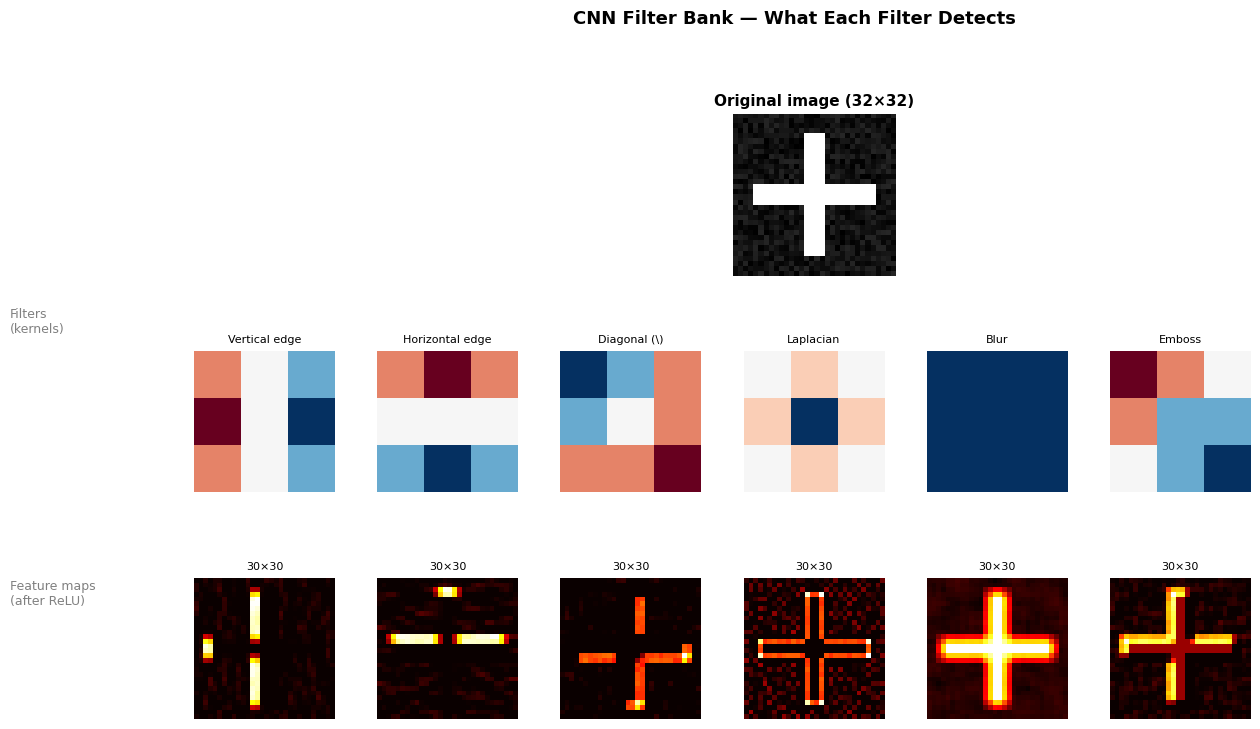

In [4]:
# ---------------------------------------------------------------
# Task B: Visualise the filter bank and all feature maps
# in a single organised grid.
# ---------------------------------------------------------------

n = len(filters)
fig = plt.figure(figsize=(16, 8))
gs = gridspec.GridSpec(3, n + 1, figure=fig,
                        hspace=0.4, wspace=0.3)

# Row 0: original image (spanning full width)
ax_orig = fig.add_subplot(gs[0, :])
ax_orig.imshow(image, cmap='gray')
ax_orig.set_title('Original image (32×32)', fontsize=11, fontweight='bold')
ax_orig.axis('off')

# Row 1: filter kernels
for col, (name, kernel) in enumerate(filters.items()):
    ax = fig.add_subplot(gs[1, col])
    ## FILL IN: display `kernel` using imshow with cmap='RdBu'
    ## Add ax.set_title(name, fontsize=8) and ax.axis('off')
    ax.imshow(kernel, cmap='RdBu', vmin=-np.max(np.abs(kernel)), vmax=np.max(np.abs(kernel)))
    ax.set_title(name, fontsize=8)
    ax.axis('off')
    

# Row 2: feature maps after ReLU
for col, (name, fm) in enumerate(feature_maps.items()):
    ax = fig.add_subplot(gs[2, col])
    ## FILL IN: display `fm` using imshow with cmap='hot'
    ## Add ax.set_title(f'{fm.shape[0]}×{fm.shape[1]}', fontsize=8)
    ## and ax.axis('off')
    ax.imshow(fm, cmap='hot')
    ax.set_title(f'{fm.shape[0]}×{fm.shape[1]}', fontsize=8)
    ax.axis('off')  
    

# Row labels
fig.text(0.01, 0.62, 'Filters\n(kernels)', va='center', ha='left',
         fontsize=9, color='gray', rotation=0)
fig.text(0.01, 0.28, 'Feature maps\n(after ReLU)', va='center', ha='left',
         fontsize=9, color='gray', rotation=0)

plt.suptitle('CNN Filter Bank — What Each Filter Detects', fontsize=13, fontweight='bold', y=1.01)
plt.show()

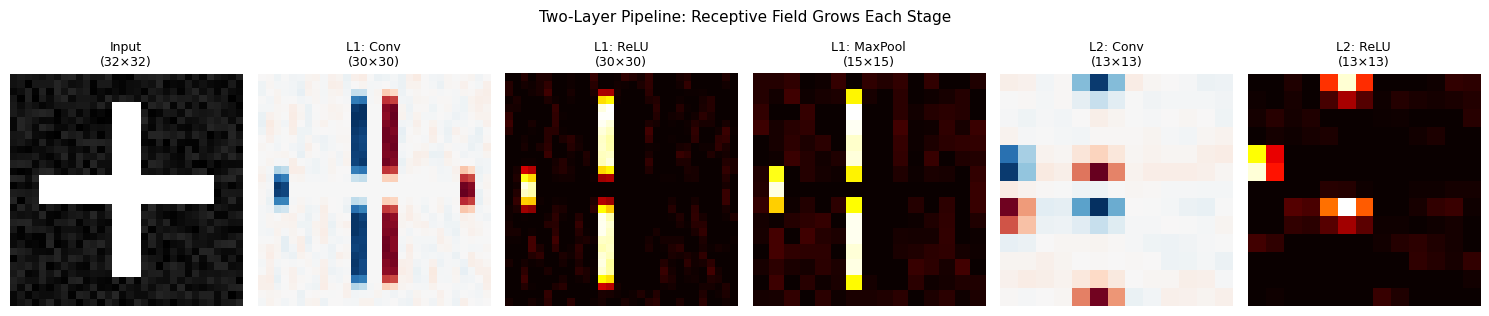


Spatial size at each stage:
  Input               : (32, 32)
  L1: Conv            : (30, 30)
  L1: ReLU            : (30, 30)
  L1: MaxPool         : (15, 15)
  L2: Conv            : (13, 13)
  L2: ReLU            : (13, 13)


In [5]:
# ---------------------------------------------------------------
# Task C: Two-layer pipeline — observe how the receptive field grows
# ---------------------------------------------------------------
# Layer 1: Conv (vertical edge) + ReLU + MaxPool
# Layer 2: Conv (horizontal edge) + ReLU
# Visualise the output at each stage.

kernel_v = filters["Vertical edge"]
kernel_h = filters["Horizontal edge"]

# --- Layer 1 ---
## FILL IN: conv2d → relu → max_pool2d (pool_size=2, stride=2)
l1_conv = conv2d(image, kernel_v, stride=1, padding=0)
l1_relu = relu(l1_conv)
l1_pool = max_pool2d(l1_relu, pool_size=2, stride=2)

# --- Layer 2 ---
## FILL IN: conv2d on l1_pool → relu
l2_conv = conv2d(l1_pool, kernel_h, stride=1, padding=0)
l2_relu = relu(l2_conv)

# --- Visualise ---
stages = [
    (image,   'Input\n(32×32)',          'gray'),
    (l1_conv, 'L1: Conv\n(30×30)',       'RdBu'),
    (l1_relu, 'L1: ReLU\n(30×30)',       'hot'),
    (l1_pool, 'L1: MaxPool\n(15×15)',    'hot'),
    (l2_conv, 'L2: Conv\n(13×13)',       'RdBu'),
    (l2_relu, 'L2: ReLU\n(13×13)',       'hot'),
]

fig, axes = plt.subplots(1, 6, figsize=(15, 3))
for ax, (data, title, cmap) in zip(axes, stages):
    ax.imshow(data, cmap=cmap)
    ax.set_title(title, fontsize=9)
    ax.axis('off')

plt.suptitle('Two-Layer Pipeline: Receptive Field Grows Each Stage', fontsize=11, y=1.05)
plt.tight_layout()
plt.show()

print(f"\nSpatial size at each stage:")
for (data, title, _) in stages:
    print(f"  {title.split(chr(10))[0]:20s}: {data.shape}")

## **Observations**

> Answer the following after running all three tasks:
>
> **Task A/B:**
> 1. Which filters produce a strong response on the horizontal bar of the cross? Which respond to the vertical bar? Does this match the structure of the kernels?
> 2. The Laplacian filter responds to *both* edges simultaneously. Looking at its kernel values, why would you expect this?
> 3. The Blur filter produces a very faint feature map after ReLU. Why does a blurring kernel produce weaker edge activations?
>
> **Task C:**
> 4. The output of Layer 2 is 13×13, starting from 32×32. Each neuron here has a receptive field you calculated in Q4. Can you see (roughly) in the Layer 2 output where the cross was, even though the spatial map is much smaller?
> 5. In general, why do we *want* the receptive field to grow as we go deeper in a CNN?

...

1. The l2 kernel/filter produces a strong response on the horizontal bar of the cross, while the l1 kernel/filter responds to the vertical bar. This matches the structure of the kernels, where l1 has values that emphasize vertical edges and l2 has values that emphasize horizontal edges.

2. The laplacian filter is symmetric in nature, and has positive values on the center and negative values on the surrounding pixels. This means it will respond strongly to areas where there is a significant change in intensity in both directions (horizontal and vertical), which is exactly what happens at the edges of the cross. 

3. The Blur filter produces a very faint feature map after ReLU because it is designed to smooth out the image, which reduces the intensity of edges. Since the cross has sharp edges, the blurring kernel will average out these edges with the surrounding pixels, resulting in a weaker activation in the feature map.

4. The output of Layer 2 is 13×13, starting from 32×32. Each neuron here has a receptive field of 8×8 (as calculated in Q4). Half of the cross (the horizontal bar) is still visible in the Layer 2 output, The horizontal bar is not much visible, but vertical is visible.

5. We want the receptive field to grow as we go deeper in a CNN because it allows neurons in later layers to capture more complex and larger-scale features. Early layers may detect simple edges or textures, while deeper layers can combine these to recognize parts of objects or even whole objects. A larger receptive field means that the network can integrate information from a wider area of the input image.

## **(Bonus) Extension: What Maximally Activates a Filter?**

A powerful interpretability technique is to find the input patch that produces the **highest activation** in a given filter — this tells you exactly what pattern the filter is tuned to detect.

Complete the function below to scan the image and find the 3×3 patch that maximally activates the Vertical Edge filter.

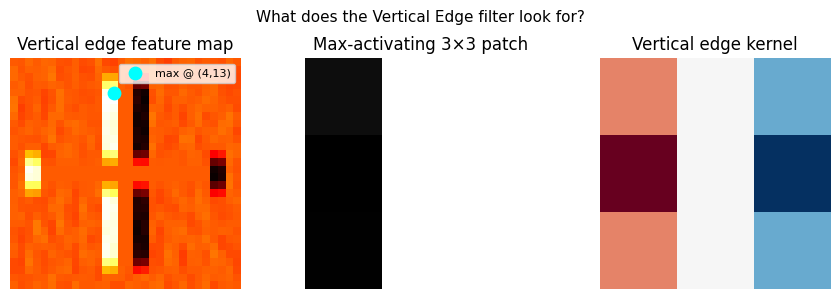

Max activation at row=4, col=13
Patch values:
[[0.06 1.   1.  ]
 [0.   1.   1.  ]
 [0.01 1.   1.  ]]


In [6]:
def find_max_activating_patch(image, kernel):
    """
    Returns the 3x3 patch from `image` that produces
    the highest response when convolved with `kernel`.
    """
    fmap = conv2d(image, kernel)  # full feature map
    K = kernel.shape[0]

    ## FILL IN:
    ## 1. Find the (row, col) of the maximum value in fmap
    ##    Hint: use np.unravel_index(np.argmax(fmap), fmap.shape)
    ## 2. Extract and return the K×K patch from image at that location
    max_loc = np.unravel_index(np.argmax(fmap), fmap.shape)
    row, col = max_loc
    best_patch = image[row:row+K, col:col+K]
    return best_patch, row, col, fmap


patch, r, c, fmap = find_max_activating_patch(image, filters["Vertical edge"])

fig, axes = plt.subplots(1, 3, figsize=(9, 3))
axes[0].imshow(fmap, cmap='hot')
axes[0].set_title('Vertical edge feature map')
axes[0].scatter([c], [r], color='cyan', s=80, zorder=5, label=f'max @ ({r},{c})')
axes[0].legend(fontsize=8)
axes[0].axis('off')

axes[1].imshow(patch, cmap='gray')
axes[1].set_title(f'Max-activating 3×3 patch')
axes[1].axis('off')

axes[2].imshow(filters["Vertical edge"], cmap='RdBu')
axes[2].set_title('Vertical edge kernel')
axes[2].axis('off')

plt.suptitle('What does the Vertical Edge filter look for?', fontsize=11)
plt.tight_layout()
plt.show()

print(f"Max activation at row={r}, col={c}")
print(f"Patch values:\n{patch.round(2)}")

**Bonus Reflection:** Does the max-activating patch visually resemble the filter kernel? What does this tell you about what the filter has "learned" to detect?

Yes, the max-activating patch visually resembles the filter kernel. This indicates that the filter has "learned" to detect patterns in the input image that closely match its own structure.